# Bell 态：让两个比特一起变化

本例从 `|00⟩` 出发，先用 H 门叠加，再用 CNOT 建立纠缠。最后观察概率、采样和 Bloch 球。

设备统一在第一格选择；可把 `apple` 改为 `cpu` 或 `cuda`。

In [2]:
from qutai import quantum, visualization

device = "apple"

## 1. 搭好电路

编号 0 是图中最上面的比特，也是测量结果最左边的一位。两个门从左到右执行。

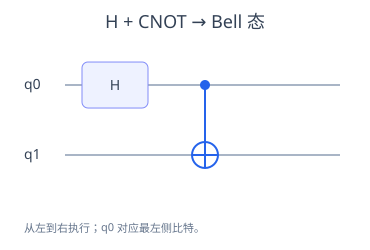

In [3]:
model = quantum.Circuit(2, [quantum.H(0), quantum.CNOT(0, 1)], device=device)
visualization.Circuit(model, title="H + CNOT → Bell 态")

## 2. 看理论概率

`run()` 执行电路，返回量子态。理想情况下只会得到 `00` 或 `11`，各占一半。

概率： [0.4999999701976776, 0.0, 0.0, 0.4999999701976776]


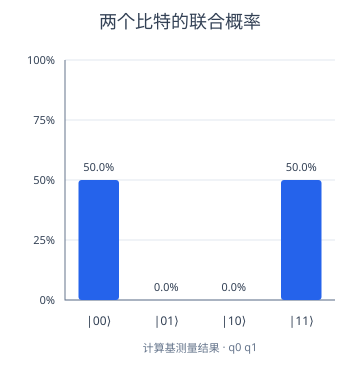

In [4]:
state = model.run()
print("概率：", state.probabilities())
visualization.Probabilities(state, title="两个比特的联合概率")

## 3. 实际采样

每次测量随机给出一种结果。有限次数的比例通常不会刚好等于理论概率。`counts()` 不修改原来的量子态。

In [5]:
print("1000 次采样：", state.counts(1000))
print("前 10 个结果：", state.sample(10))

1000 次采样： {'00': 512, '11': 488}
前 10 个结果： ['00', '00', '11', '11', '11', '00', '00', '11', '11', '11']


## 4. 单看其中一个比特

整体是纯态，但单独看任意一个纠缠比特都是最大混合态，所以它的 Bloch 向量位于球心。这和“整个量子态在球心”不是一回事。

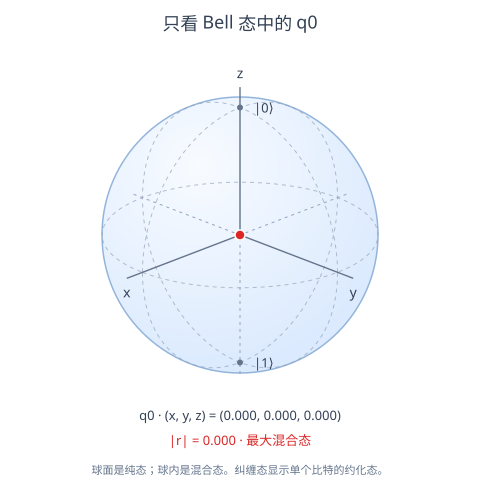

In [6]:
visualization.Bloch(state, wire=0, title="只看 Bell 态中的 q0")